# Predicting Bank Default Risk in Ukraine (2009-2025) 
**Project Overview:**
This project aims to identify early warning indicators of bank defaults using Machine Learning. Unlike standard clean datasets, this analysis is built on raw, real-world financial statements extracted from the National Bank of Ukraine (NBU) over a 16-year period. 

**Core Objectives:**
1. Perform complex ETL (Extract, Transform, Load) on unstructured historical financial reports.
2. Engineer key financial metrics (ROA, ROE, Liquidity Ratio, etc.) from raw assets and liabilities.
3. Build a predictive model to assess the probability of a bank's liquidation or insolvency in the following year.

In [1]:
import pandas as pd
import numpy as np
import os
import re
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import roc_auc_score, classification_report

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.family'] = 'sans-serif'

base_path = "data/Aggregation_new"
licences_path = "data/export_banks_licences.xlsx"
RANDOM_STATE = 42

c:\Users\pinch\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def get_target_file(year_path):
    files = os.listdir(year_path)
    xlsx_files = [f for f in files if f.endswith('.xlsx') or f.endswith('.xls')]
    
    for f in xlsx_files:
        if re.search(r'aggregation_\d{4}-01-01', f):
            return os.path.join(year_path, f), 'new'
        if re.search(r'^\d{4}0101\.', f):
            return os.path.join(year_path, f), 'new'
    
    for f in xlsx_files:
        if re.search(r'^0110\d{4}', f):
            return os.path.join(year_path, f), 'old'
        if re.search(r'^\d{4}1001\.', f):
            return os.path.join(year_path, f), 'old'
    
    return None, None

def find_sheet(sheet_names, keywords):
    for sheet in sheet_names:
        for kw in keywords:
            if kw.lower() in sheet.lower().strip():
                return sheet
    return None

def find_col(df, keywords, header_rows=8):
    for i in range(df.shape[1]):
        combined = ' '.join(
            df.iloc[:header_rows, i].fillna('').astype(str).tolist()
        ).strip().lower()
        if any(kw.lower() in combined for kw in keywords):
            return i
    return None

def find_bank_col_and_start(df):
    header_row = None
    bank_col = 2 
    for i in range(15):
        row = df.iloc[i].fillna('').astype(str).tolist()
        for j, val in enumerate(row):
            if val.strip().lower() in ['назва банку', 'банк']:
                header_row = i
                bank_col = j
                break
        if header_row is not None:
            break
    
    data_start = None
    for i in range(df.shape[0]):
        if str(df.iloc[i, 0]).strip() == '1':
            data_start = i
            break
    
    return bank_col, data_start

def find_col_exclude(df, keywords, exclude=[], header_rows=8):
    for i in range(df.shape[1]):
        combined = ' '.join(
            df.iloc[:header_rows, i].fillna('').astype(str).tolist()
        ).strip().lower()
        if any(kw.lower() in combined for kw in keywords):
            if not any(ex.lower() in combined for ex in exclude):
                return i
    return None

def find_all_cols(df, keywords, header_rows=8):
    result = []
    for i in range(df.shape[1]):
        combined = ' '.join(
            df.iloc[:header_rows, i].fillna('').astype(str).tolist()
        ).strip().lower()
        if any(kw.lower() in combined for kw in keywords):
            result.append(i)
    return result

In [3]:
def parse_one_file(file_path, year):
    xl = pd.ExcelFile(file_path)

    s_assets = find_sheet(xl.sheet_names, ["актив"])
    s_liab = find_sheet(xl.sheet_names, ["зобов"])
    s_cap = find_sheet(xl.sheet_names, ["капітал"])
    s_fin = find_sheet(xl.sheet_names, ["фінрез", "фінансові результати"])

    df_a = pd.read_excel(file_path, sheet_name=s_assets, header=None)
    df_l = pd.read_excel(file_path, sheet_name=s_liab, header=None)
    df_c = pd.read_excel(file_path, sheet_name=s_cap, header=None)
    df_f = pd.read_excel(file_path, sheet_name=s_fin, header=None)

    bank_col_a, data_start_a = find_bank_col_and_start(df_a)
    bank_col_l, data_start_l = find_bank_col_and_start(df_l)
    bank_col_c, data_start_c = find_bank_col_and_start(df_c)
    bank_col_f, data_start_f = find_bank_col_and_start(df_f)

    col_assets = find_col(df_a, ["усього активів", "загальні активи"])
    col_cash = find_col(df_a, ["грошові кошти та їх еквівалент"])
    col_loans = find_col(df_a, ["кредити та заборгованість клієнтів"])
    
    col_reserves_list = find_all_cols(df_a, [
        "резерви під знецінення кредитів та заборгованості",
        "резерви під знецінення кредитів"
    ])

    col_liab = find_col(df_l, ["усього зобов"])
    col_deposits = find_col(df_l, ["кошти клієнтів", "кошти фізичних"])
    col_equity = find_col(df_c, ["усього власного капіталу", "усього капіталу"])

    col_profit = find_col_exclude(
        df_f,
        ["прибуток після оподаткування", "прибуток/(збиток) після оподатку", "прибуток/(збиток) після"],
        exclude=["до оподаткування", "від припиненої", "первісного"],
    )
    if col_profit is None:
        col_profit = find_col_exclude(
            df_f,
            ["прибуток/(збиток)"],
            exclude=["до оподаткування", "від припиненої", "первісного", "після оподатку"],
        )

    col_int_income = find_col(df_f, ["процентні доходи"])
    col_int_expense = find_col_exclude(df_f, ["процентні витрати"], exclude=["чистий", "чисті"])
    col_admin = find_col(df_f, ["адміністративні та інші", "адміністра"])

    def extract_banks(df, bank_col, data_start, cols_dict, reserve_cols=None):
        result = {}
        if data_start is None or bank_col is None:
            return result
        for i in range(data_start, df.shape[0]):
            bank = str(df.iloc[i, bank_col]).strip()
            if not bank or bank.lower() == "nan":
                continue
            if any(x in bank.lower() for x in ["група", "усього", "разом", "щодо"]):
                continue
            row = {
                k: pd.to_numeric(df.iloc[i, v], errors="coerce") if v is not None else None
                for k, v in cols_dict.items()
            }
            # Резерви за кредитами сумуються з усіх релевантних колонок
            if reserve_cols:
                vals = [pd.to_numeric(df.iloc[i, c], errors="coerce") for c in reserve_cols]
                vals = [v for v in vals if pd.notna(v)]
                row["loan_reserves"] = sum(vals) if vals else None
            result[bank] = row
        return result

    assets_data = extract_banks(df_a, bank_col_a, data_start_a, {
        "total_assets": col_assets,
        "cash": col_cash,
        "loans": col_loans,
    }, reserve_cols=col_reserves_list)

    liab_data = extract_banks(df_l, bank_col_l, data_start_l, {
        "total_liab": col_liab,
        "deposits": col_deposits
    })
    cap_data = extract_banks(df_c, bank_col_c, data_start_c, {
        "equity": col_equity
    })
    fin_data = extract_banks(df_f, bank_col_f, data_start_f, {
        "net_income": col_profit,
        "interest_income": col_int_income,
        "interest_expense": col_int_expense,
        "admin_expenses": col_admin,
    })

    rows = []
    for bank, vals in assets_data.items():
        row = {"bank_name": bank, "year": year}
        row.update(vals)
        row.update(liab_data.get(bank, {}))
        row.update(cap_data.get(bank, {}))
        row.update(fin_data.get(bank, {}))
        rows.append(row)

    return pd.DataFrame(rows)

In [4]:
all_data = []

for year_folder in sorted(os.listdir(base_path)):
    year_path = os.path.join(base_path, year_folder)
    if not os.path.isdir(year_path):
        continue

    file_path, file_type = get_target_file(year_path)
    if file_path is None:
        continue

    try:
        year_df = parse_one_file(file_path, int(year_folder))
        all_data.append(year_df)
        print(f"{year_folder}: оброблено {len(year_df)} банків")
    except Exception as error:
        print(f"{year_folder}: помилка обробки - {error}")

df_all = pd.concat(all_data, ignore_index=True)

print(f"Загальна кількість спостережень: {len(df_all)}")
print(f"Кількість унікальних банків: {df_all['bank_name'].nunique()}")
print(f"Період дослідження: {df_all['year'].min()}-{df_all['year'].max()}")

2009: оброблено 181 банків
2010: оброблено 176 банків
2011: оброблено 175 банків
2012: оброблено 175 банків
2013: оброблено 178 банків
2014: оброблено 166 банків
2015: оброблено 131 банків
2016: оброблено 100 банків
2017: оброблено 85 банків
2018: оброблено 83 банків
2019: оброблено 79 банків
2020: оброблено 77 банків
2021: оброблено 75 банків
2022: оброблено 71 банків
2023: оброблено 67 банків
2024: оброблено 67 банків
2025: оброблено 64 банків
Загальна кількість спостережень: 1950
Кількість унікальних банків: 462
Період дослідження: 2009-2025


In [5]:
df_bankrupt = pd.read_excel(licences_path, skiprows=1)
df_bankrupt.columns = ['mfo', 'name', 'history', 'status', 'link']

print("Розподіл банків за статусами у реєстрі НБУ:")
print(df_bankrupt['status'].value_counts())

Розподіл банків за статусами у реєстрі НБУ:
status
Виключений з реєстру    159
Платоспроможний          58
Ліквідація               53
Неплатоспроможний         2
Name: count, dtype: int64


## 1. Feature Engineering & Data Wrangling
Data provided by regulatory bodies often contains inconsistencies, formatting changes, and missing values across different years. 

In this section, I:
* Standardize bank names across 16 years of changing registries.
* Define the Target Variable: `1` for Insolvent/Liquidated banks, `0` for Solvent banks.
* Engineer advanced banking risk indicators based on raw NBU data, such as **ROA (Return on Assets)**, **ROE (Return on Equity)**, and **Reserves/Loans Ratio**.

In [6]:
print("1. Очищення назв банків та формування цільової змінної")

def clean_bank_name(name):
    if pd.isna(name):
        return ""
    name = str(name).upper()
    name = re.sub(r'[^А-ЯІЇЄҐA-Z]', '', name)
    for word in ['ПАТ', 'АТ', 'АКБ', 'КБ', 'ПУАТ', 'ЗАТ', 'ВАТ']:
        name = name.replace(word, '')
    return name

df_all['clean_name'] = df_all['bank_name'].apply(clean_bank_name)
df_bankrupt['clean_name'] = df_bankrupt['name'].apply(clean_bank_name)

target_map = {
    'Ліквідація': 1,
    'Неплатоспроможний': 1,
    'Платоспроможний': 0,
}

df_bankrupt['target'] = df_bankrupt['status'].map(target_map)
df_labels = df_bankrupt.dropna(subset=['target'])[['clean_name', 'target']]
df_merged = df_all.merge(df_labels, on='clean_name', how='inner')

print("2. Формування мітки ризику для наступного доступного спостереження")
df_merged = df_merged.sort_values(by=['clean_name', 'year'])
df_merged['target_next_year'] = df_merged.groupby('clean_name')['target'].shift(-1)

print("3. Розрахунок фінансових індикаторів")
df_merged['ROA'] = df_merged['net_income'] / df_merged['total_assets'].replace(0, np.nan)
df_merged['ROE'] = df_merged['net_income'] / df_merged['equity'].replace(0, np.nan)
df_merged['equity_ratio'] = df_merged['equity'] / df_merged['total_assets'].replace(0, np.nan)
df_merged['reserves_ratio'] = df_merged['loan_reserves'].abs() / df_merged['loans'].replace(0, np.nan)
df_merged['liquidity_ratio'] = df_merged['cash'] / df_merged['total_assets'].replace(0, np.nan)

base_features = [
    'total_assets', 'cash', 'loans', 'loan_reserves', 'total_liab',
    'deposits', 'equity', 'net_income', 'interest_income',
    'interest_expense', 'admin_expenses',
]

advanced_features = base_features + ['ROA', 'ROE', 'equity_ratio', 'reserves_ratio', 'liquidity_ratio']
df_ml = df_merged.dropna(subset=advanced_features + ['target_next_year'])

print(f"Розмір фінального датасету: {df_ml.shape[0]} спостережень")

# Часове розбиття дозволяє перевірити модель на пізнішому періоді.
df_ml_sorted = df_ml.sort_values('year')
train_df = df_ml_sorted[df_ml_sorted['year'] <= 2019]
test_df = df_ml_sorted[df_ml_sorted['year'] >= 2020]

X_train = train_df[advanced_features]
y_train = train_df['target_next_year']
X_test = test_df[advanced_features]
y_test = test_df['target_next_year']

print(f"Навчальна вибірка: {len(X_train)} спостережень ({train_df['year'].min()}-{train_df['year'].max()})")
print(f"Тестова вибірка: {len(X_test)} спостережень ({test_df['year'].min()}-{test_df['year'].max()})")
print(f"\nРозподіл класів у train:\n{y_train.value_counts()}")
print(f"\nРозподіл класів у test:\n{y_test.value_counts()}")

1. Очищення назв банків та формування цільової змінної
2. Формування мітки ризику для наступного доступного спостереження
3. Розрахунок фінансових індикаторів
Розмір фінального датасету: 916 спостережень
Навчальна вибірка: 631 спостережень (2009-2019)
Тестова вибірка: 285 спостережень (2020-2024)

Розподіл класів у train:
target_next_year
0.0    364
1.0    267
Name: count, dtype: int64

Розподіл класів у test:
target_next_year
0.0    256
1.0     29
Name: count, dtype: int64


## 2. Out-of-Time (OOT) Validation Strategy
In credit and risk modeling, standard random train-test splits lead to data leakage. To ensure robustness, the dataset is split temporally:
* **Training Set (2009 - 2019):** Allows the algorithm to learn patterns from systemic financial crises (e.g., the 2014-2015 Ukrainian banking crisis).
* **Test Set (2020 - 2024):** Evaluates the model's performance on unseen, highly volatile periods affected by systemic shocks ("Black Swan" events like COVID-19 and the 2022 martial law).

--- Розпочинаємо розширений розвідувальний аналіз даних (EDA) ---


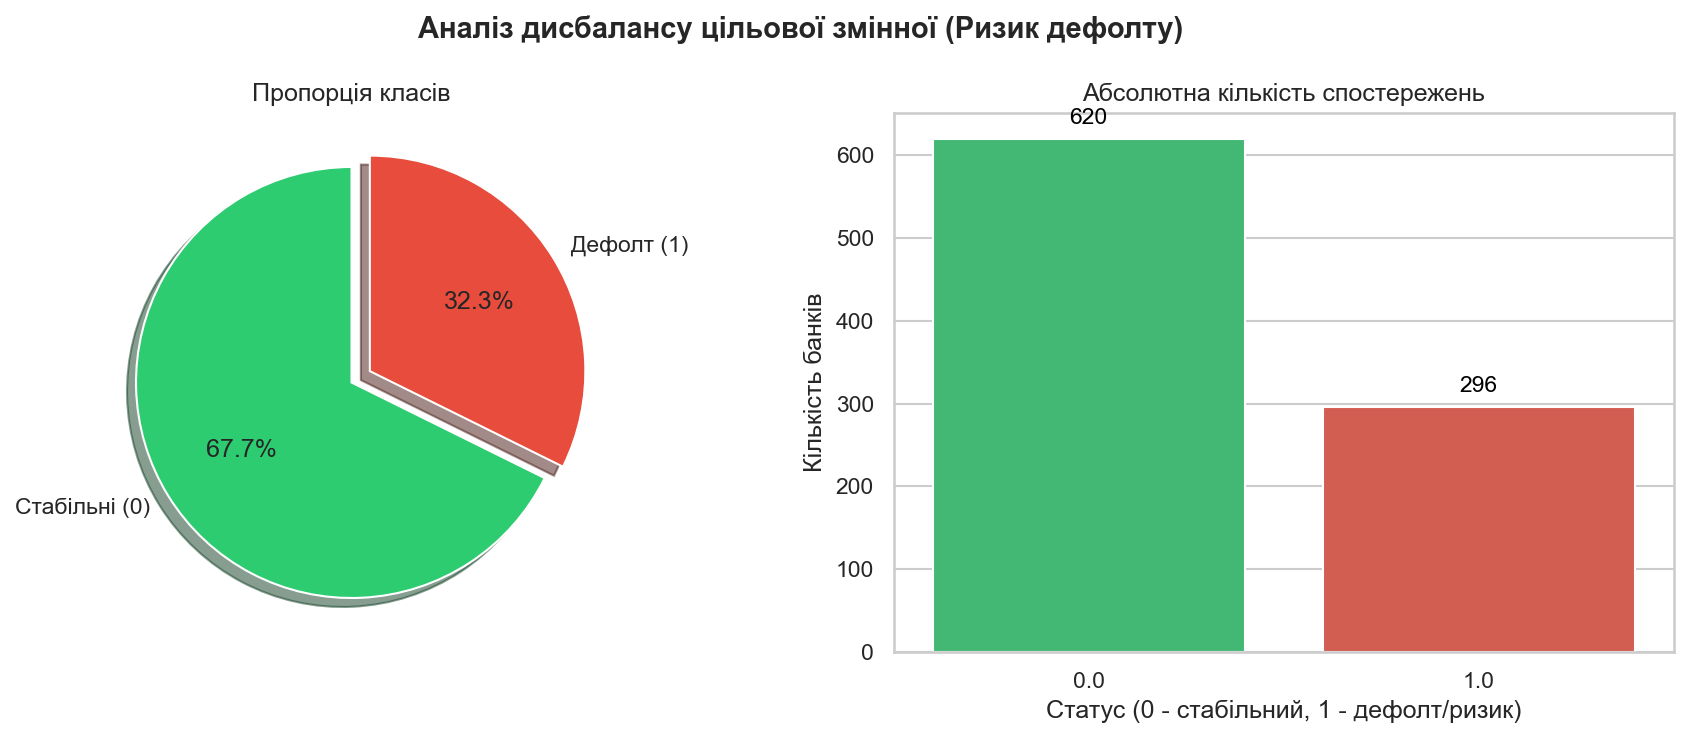

KeyboardInterrupt: 

In [7]:
# Академічний стиль графіків
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.family'] = 'sans-serif'

print("--- Розпочинаємо розширений розвідувальний аналіз даних (EDA) ---")

# Ключові фінансові коефіцієнти для EDA
camels_features = ['ROA', 'ROE', 'equity_ratio', 'reserves_ratio', 'liquidity_ratio']


# 1. Графік дисбалансу класів (Кругова + Стовпчикова діаграма)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Аналіз дисбалансу цільової змінної (Ризик дефолту)', fontsize=14, fontweight='bold')

# Кругова діаграма
target_counts = df_ml['target_next_year'].value_counts()
axes[0].pie(target_counts, labels=['Стабільні (0)', 'Дефолт (1)'], autopct='%1.1f%%', 
            colors=['#2ecc71', '#e74c3c'], startangle=90, explode=(0, 0.1), shadow=True)
axes[0].set_title('Пропорція класів')

# Стовпчикова діаграма
sns.countplot(data=df_ml, x='target_next_year', hue='target_next_year', palette=['#2ecc71', '#e74c3c'], legend=False, ax=axes[1])
axes[1].set_title('Абсолютна кількість спостережень')
axes[1].set_xlabel('Статус (0 - стабільний, 1 - дефолт/ризик)')
axes[1].set_ylabel('Кількість банків')

for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, color='black', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()


# 2. Матриця кореляцій (Теплова карта з маскою)

plt.figure(figsize=(10, 8))
# Кореляції між фінансовими ознаками
corr_matrix = df_ml[advanced_features].corr()

# Маска приховує дублювання кореляцій у верхньому трикутнику
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", 
            vmax=1, vmin=-1, center=0, square=True, linewidths=.5, cbar_kws={"shrink": .7})
plt.title('Матриця парних кореляцій фінансових ознак', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()


# 3. Boxplots: Порівняння CAMELS у здорових та дефолтних банків

# Порівняння розподілів ключових коефіцієнтів
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Розподіл фінансових коефіцієнтів у розрізі статусу банку (Boxplots)', fontsize=16, fontweight='bold')
axes = axes.flatten()

camels_titles = {
    'ROA': 'Рентабельність активів (ROA)',
    'ROE': 'Рентабельність капіталу (ROE)',
    'equity_ratio': 'Достатність капіталу',
    'reserves_ratio': 'Частка резервів (Ризиковість)',
    'liquidity_ratio': 'Показник ліквідності'
}

for i, col in enumerate(camels_features):
    # showfliers=False ховає екстремальні викиди, щоб було видно саму структуру "ящика"
    sns.boxplot(x='target_next_year', y=col, hue='target_next_year', data=df_ml, ax=axes[i], 
                palette=['#2ecc71', '#e74c3c'], showfliers=False, legend=False)
    axes[i].set_title(camels_titles[col], fontsize=12)
    axes[i].set_xlabel('Статус (0 - Стабільний, 1 - Дефолт)')
    axes[i].set_ylabel('Значення коефіцієнта')

# Видаляємо порожню шосту вісь
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()


# 4. KDE Plots: Форма розподілу показників

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Щільність розподілу (KDE) фінансових показників', fontsize=16, fontweight='bold')
axes = axes.flatten()

for i, col in enumerate(camels_features):
    # Графіки щільності показують форму розподілу
    sns.kdeplot(data=df_ml, x=col, hue='target_next_year', ax=axes[i], 
                fill=True, common_norm=False, palette=['#2ecc71', '#e74c3c'], alpha=0.5)
    axes[i].set_title(camels_titles[col], fontsize=12)
    axes[i].set_xlabel('Значення коефіцієнта')
    axes[i].set_ylabel('Щільність')
    # Обмежуємо вісь X процентилями, щоб викиди не спотворювали масштаб
    axes[i].set_xlim(df_ml[col].quantile(0.05), df_ml[col].quantile(0.95))

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

print("--- EDA завершено. Графіки готові для експорту в диплом ---")

--- 4. Навчання та порівняння алгоритмів ---
Навчання Логістичної регресії...
Навчання Random Forest...
Навчання XGBoost...


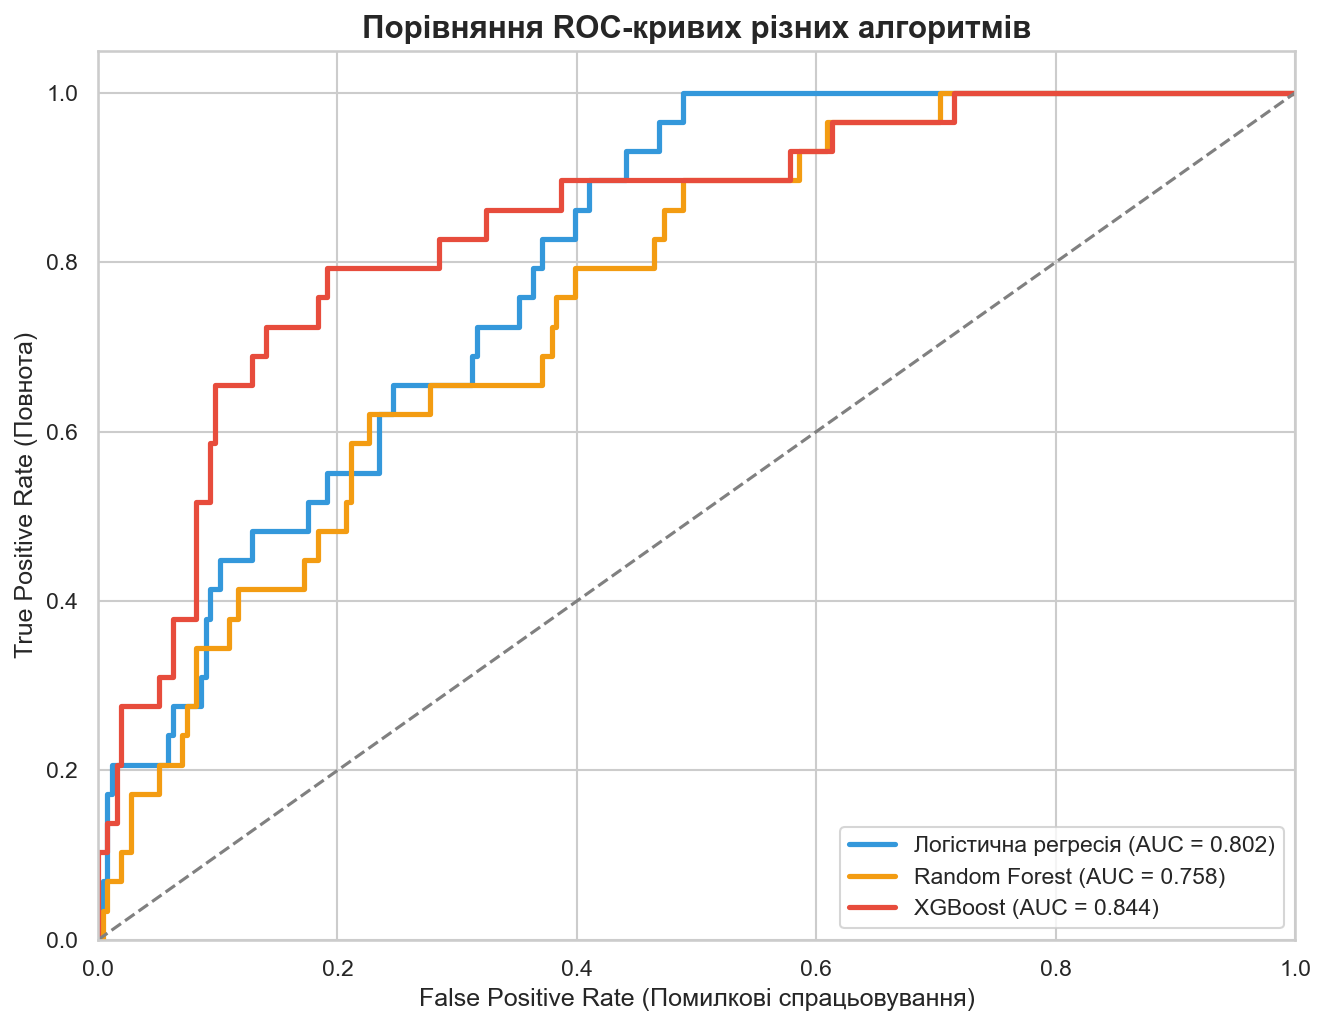


--- Фінальні метрики XGBoost (з урахуванням дисбалансу) ---
              precision    recall  f1-score   support

         0.0       0.92      0.94      0.93       256
         1.0       0.38      0.31      0.34        29

    accuracy                           0.88       285
   macro avg       0.65      0.63      0.64       285
weighted avg       0.87      0.88      0.87       285



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve

print("--- 4. Навчання та порівняння алгоритмів ---")

# Для логістичної регресії ознаки масштабуються
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Коефіцієнт дисбалансу класів для XGBoost
imbalance_ratio = y_train.value_counts()[0.0] / y_train.value_counts()[1.0]

print("Навчання Логістичної регресії...")
model_lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model_lr.fit(X_train_scaled, y_train)
lr_probs = model_lr.predict_proba(X_test_scaled)[:, 1]

print("Навчання Random Forest...")
model_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', max_depth=5, random_state=42)
model_rf.fit(X_train, y_train)
rf_probs = model_rf.predict_proba(X_test)[:, 1]

print("Навчання XGBoost...")
model_xgb = xgb.XGBClassifier(
    n_estimators=100, 
    max_depth=4, 
    learning_rate=0.1, 
    scale_pos_weight=imbalance_ratio,
    random_state=42, 
    eval_metric='auc'
)
model_xgb.fit(X_train, y_train)
xgb_probs = model_xgb.predict_proba(X_test)[:, 1]


# Загальний графік ROC-кривих

plt.figure(figsize=(9, 7))

# ROC-криві для кожної моделі
for probs, name, color in zip([lr_probs, rf_probs, xgb_probs], 
                              ['Логістична регресія', 'Random Forest', 'XGBoost'], 
                              ['#3498db', '#f39c12', '#e74c3c']):
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_score = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, color=color, lw=2.5, label=f'{name} (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], color='grey', lw=1.5, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Помилкові спрацьовування)', fontsize=12)
plt.ylabel('True Positive Rate (Повнота)', fontsize=12)
plt.title('Порівняння ROC-кривих різних алгоритмів', fontsize=15, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()

# Базові метрики XGBoost за стандартного порогу 0.5
print("\n--- Фінальні метрики XGBoost (з урахуванням дисбалансу) ---")
xgb_preds = model_xgb.predict(X_test)
print(classification_report(y_test, xgb_preds))

--- 4.1. Розширене порівняння моделей для задачі ризику дефолту ---


,model,threshold,ROC-AUC,PR-AUC,precision_default,recall_default,F1_default,F2_default,balanced_accuracy
2,XGBoost,0.5,0.844,0.447,0.375,0.310,0.340,0.321,0.626
0,Logistic Regression,0.5,0.802,0.345,0.333,0.448,0.382,0.419,0.673
1,Random Forest,0.5,0.758,0.259,0.303,0.345,0.323,0.336,0.627


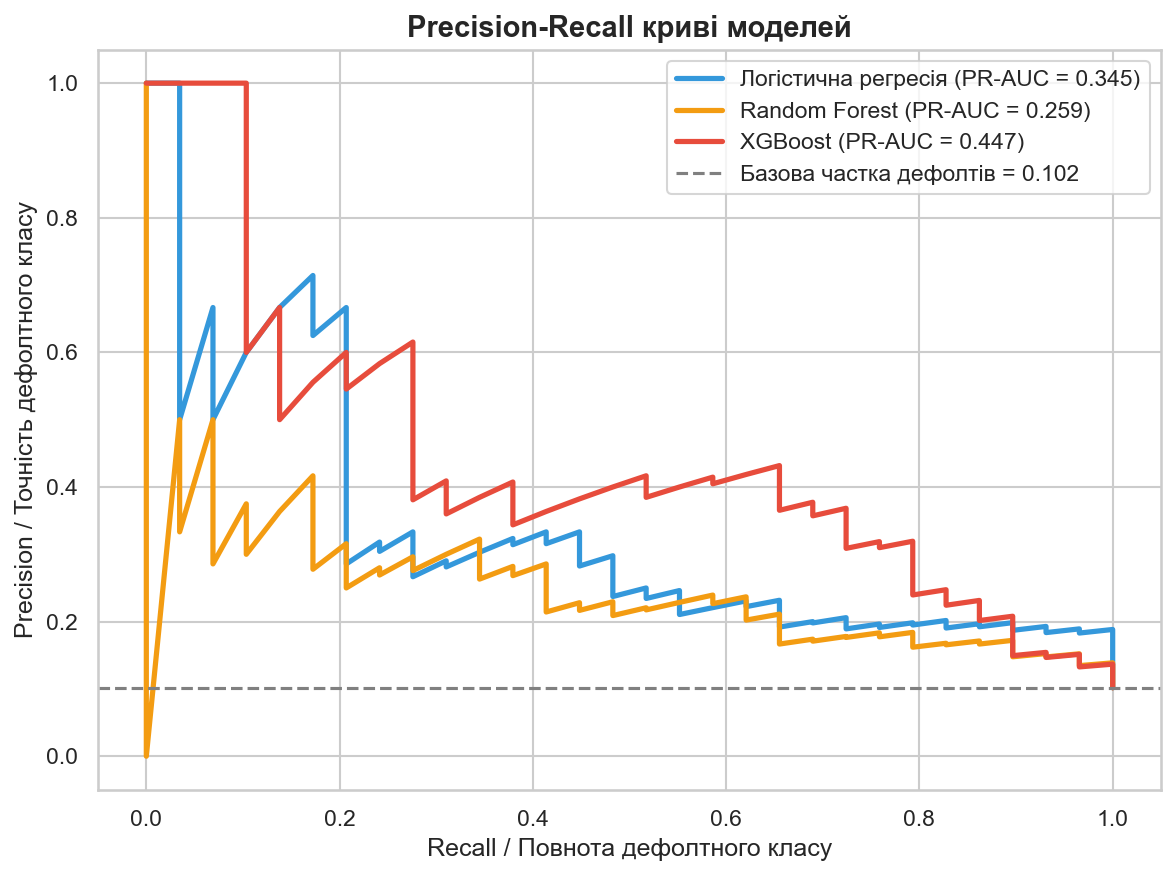

In [ ]:
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    fbeta_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

print("--- 4.1. Розширене порівняння моделей для задачі ризику дефолту ---")

model_probabilities = {
    'Logistic Regression': lr_probs,
    'Random Forest': rf_probs,
    'XGBoost': xgb_probs,
}

def evaluate_model(name, probs, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    return {
        'model': name,
        'threshold': threshold,
        'ROC-AUC': roc_auc_score(y_test, probs),
        'PR-AUC': average_precision_score(y_test, probs),
        'precision_default': precision_score(y_test, preds, zero_division=0),
        'recall_default': recall_score(y_test, preds, zero_division=0),
        'F1_default': f1_score(y_test, preds, zero_division=0),
        'F2_default': fbeta_score(y_test, preds, beta=2, zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(y_test, preds),
    }

model_results = pd.DataFrame([
    evaluate_model(name, probs, threshold=0.50)
    for name, probs in model_probabilities.items()
]).sort_values('ROC-AUC', ascending=False)

display(model_results.round(3))

plt.figure(figsize=(8, 6))
for probs, name, color in zip(
    [lr_probs, rf_probs, xgb_probs],
    ['Логістична регресія', 'Random Forest', 'XGBoost'],
    ['#3498db', '#f39c12', '#e74c3c']
):
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, probs)
    pr_auc = average_precision_score(y_test, probs)
    plt.plot(recall_curve, precision_curve, color=color, lw=2.5, label=f'{name} (PR-AUC = {pr_auc:.3f})')

baseline = y_test.mean()
plt.axhline(baseline, color='grey', linestyle='--', lw=1.5, label=f'Базова частка дефолтів = {baseline:.3f}')
plt.xlabel('Recall / Повнота дефолтного класу')
plt.ylabel('Precision / Точність дефолтного класу')
plt.title('Precision-Recall криві моделей', fontsize=14, fontweight='bold')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

--- 4.2. Підбір оптимального порогу для всіх моделей за F2-score ---


,model,threshold,ROC-AUC,PR-AUC,precision_default,recall_default,F1_default,F2_default,balanced_accuracy
0,XGBoost,0.28,0.844,0.447,0.368,0.724,0.488,0.607,0.792
1,Logistic Regression,0.26,0.802,0.345,0.188,1.000,0.317,0.537,0.756
2,Random Forest,0.17,0.758,0.259,0.183,0.793,0.297,0.475,0.695



Найкраща модель за F2-score після підбору порогу:


,model,threshold,ROC-AUC,PR-AUC,precision_default,recall_default,F1_default,F2_default,balanced_accuracy
0,XGBoost,0.28,0.844,0.447,0.368,0.724,0.488,0.607,0.792


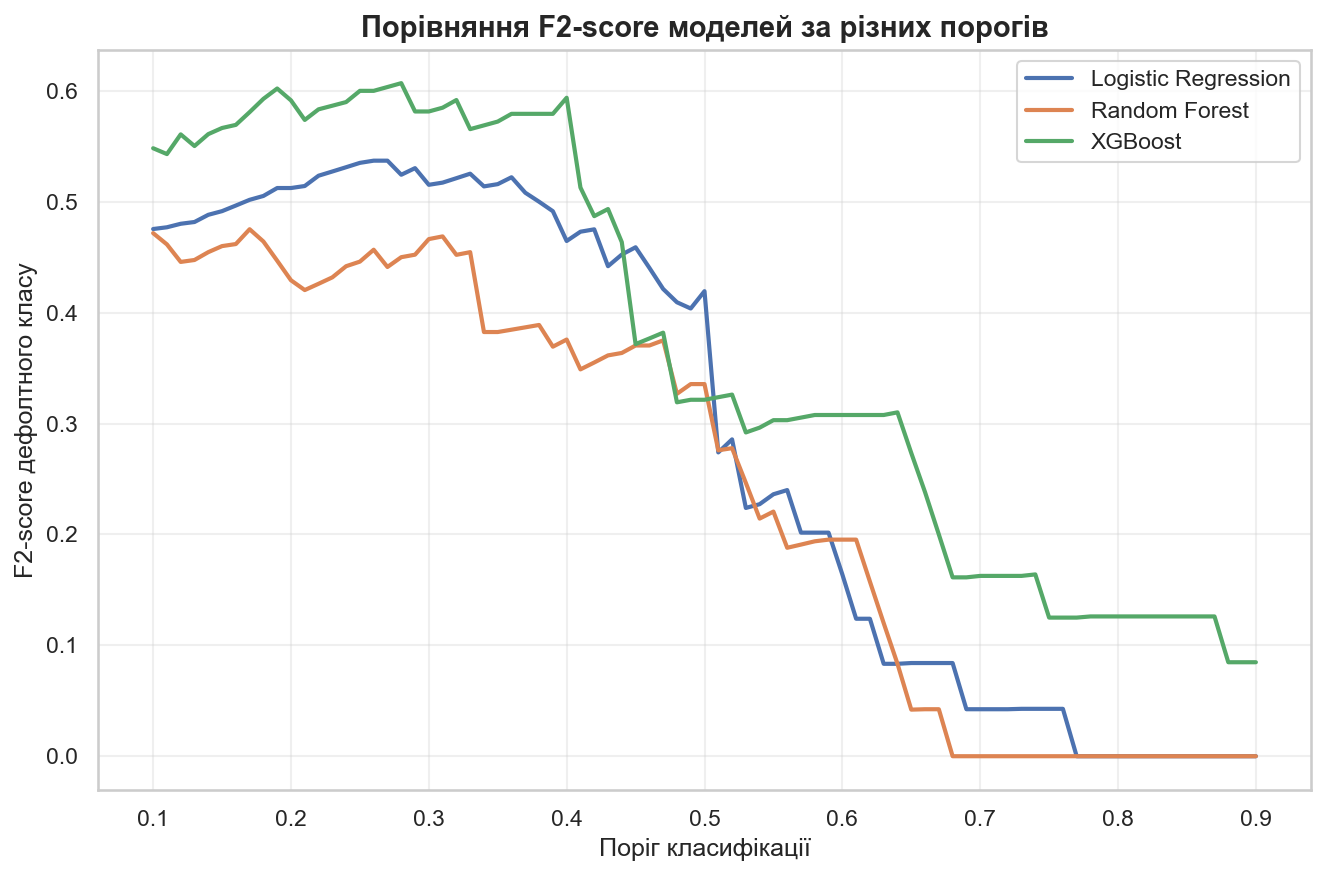

--- Порівняння моделей при стандартному та оптимальному порогах ---


,threshold_type,model,threshold,ROC-AUC,PR-AUC,precision_default,recall_default,F1_default,F2_default,balanced_accuracy
4,best_F2,Logistic Regression,0.26,0.802,0.345,0.188,1.000,0.317,0.537,0.756
0,standard_0.50,Logistic Regression,0.50,0.802,0.345,0.333,0.448,0.382,0.419,0.673
5,best_F2,Random Forest,0.17,0.758,0.259,0.183,0.793,0.297,0.475,0.695
1,standard_0.50,Random Forest,0.50,0.758,0.259,0.303,0.345,0.323,0.336,0.627
3,best_F2,XGBoost,0.28,0.844,0.447,0.368,0.724,0.488,0.607,0.792
2,standard_0.50,XGBoost,0.50,0.844,0.447,0.375,0.310,0.340,0.321,0.626


In [ ]:
print("--- 4.2. Підбір оптимального порогу для всіх моделей за F2-score ---")

def find_best_threshold_by_f2(name, probs, thresholds=np.arange(0.10, 0.91, 0.01)):
    rows = []
    for threshold in thresholds:
        rows.append(evaluate_model(name, probs, threshold=threshold))
    report = pd.DataFrame(rows)
    best_row = report.loc[report['F2_default'].idxmax()].copy()
    return best_row, report

best_threshold_rows = []
threshold_reports = {}

for model_name, probs in model_probabilities.items():
    best_row, report = find_best_threshold_by_f2(model_name, probs)
    best_threshold_rows.append(best_row)
    threshold_reports[model_name] = report

best_threshold_comparison = (
    pd.DataFrame(best_threshold_rows)
    .sort_values('F2_default', ascending=False)
    .reset_index(drop=True)
)

display(best_threshold_comparison.round(3))

print("\nНайкраща модель за F2-score після підбору порогу:")
display(best_threshold_comparison.head(1).round(3))

plt.figure(figsize=(9, 6))
for model_name, report in threshold_reports.items():
    plt.plot(report['threshold'], report['F2_default'], lw=2, label=model_name)

plt.xlabel('Поріг класифікації')
plt.ylabel('F2-score дефолтного класу')
plt.title('Порівняння F2-score моделей за різних порогів', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("--- Порівняння моделей при стандартному та оптимальному порогах ---")

default_threshold_comparison = pd.DataFrame([
    evaluate_model(name, probs, threshold=0.50)
    for name, probs in model_probabilities.items()
])
default_threshold_comparison['threshold_type'] = 'standard_0.50'
best_threshold_comparison['threshold_type'] = 'best_F2'

comparison_before_after = pd.concat([default_threshold_comparison, best_threshold_comparison], ignore_index=True)
comparison_before_after = comparison_before_after[
    ['threshold_type', 'model', 'threshold', 'ROC-AUC', 'PR-AUC', 'precision_default',
     'recall_default', 'F1_default', 'F2_default', 'balanced_accuracy']
]

display(comparison_before_after.sort_values(['model', 'threshold_type']).round(3))

In [ ]:
from sklearn.model_selection import GridSearchCV

print("--- 5. Тюнінг гіперпараметрів для XGBoost (GridSearchCV) ---")

param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300]
}

print("Запускаємо перебір 27 комбінацій гіперпараметрів...")

grid_search = GridSearchCV(
    estimator=xgb.XGBClassifier(
        scale_pos_weight=imbalance_ratio,
        random_state=42,
        eval_metric='auc'
    ),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Тюнінг успішно завершено")
print(f"Найкращі гіперпараметри: {grid_search.best_params_}")
print(f"ROC-AUC на крос-валідації: {grid_search.best_score_:.4f}")

best_xgb = grid_search.best_estimator_

final_probs = best_xgb.predict_proba(X_test)[:, 1]

print("--- Результати фінальної оптимізованої моделі ---")
print(f"Фінальний ROC-AUC: {roc_auc_score(y_test, final_probs):.4f}")

# Поріг 0.3 використовується як початковий варіант для підвищення recall дефолтного класу
final_preds = (final_probs >= 0.3).astype(int)
print("\nЗвіт класифікації (поріг відсікання = 0.3):")
print(classification_report(y_test, final_preds))

--- 5. Тюнінг гіперпараметрів для XGBoost (GridSearchCV) ---
Запускаємо перебір 27 комбінацій гіперпараметрів...
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Тюнінг успішно завершено
Найкращі гіперпараметри: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}
ROC-AUC на крос-валідації: 0.7901
--- Результати фінальної оптимізованої моделі ---
Фінальний ROC-AUC: 0.8390

Звіт класифікації (поріг відсікання = 0.3):
              precision    recall  f1-score   support

         0.0       0.96      0.84      0.90       256
         1.0       0.34      0.72      0.46        29

    accuracy                           0.83       285
   macro avg       0.65      0.78      0.68       285
weighted avg       0.90      0.83      0.85       285



--- 5.1. Обґрунтований вибір порогу для фінальної XGBoost-моделі ---
PR-AUC фінальної XGBoost-моделі: 0.4375
Рекомендований поріг за максимумом F2-score: 0.34

Найкращі пороги за F2-score для фінальної XGBoost-моделі:


,model,threshold,ROC-AUC,PR-AUC,precision_default,recall_default,F1_default,F2_default,balanced_accuracy
24,XGBoost final,0.34,0.839,0.438,0.382,0.724,0.500,0.614,0.796
23,XGBoost final,0.33,0.839,0.438,0.375,0.724,0.494,0.610,0.794
22,XGBoost final,0.32,0.839,0.438,0.368,0.724,0.488,0.607,0.792
27,XGBoost final,0.37,0.839,0.438,0.400,0.690,0.506,0.602,0.786
21,XGBoost final,0.31,0.839,0.438,0.350,0.724,0.472,0.597,0.786
26,XGBoost final,0.36,0.839,0.438,0.377,0.690,0.488,0.592,0.780
19,XGBoost final,0.29,0.839,0.438,0.339,0.724,0.462,0.590,0.782
20,XGBoost final,0.30,0.839,0.438,0.339,0.724,0.462,0.590,0.782
25,XGBoost final,0.35,0.839,0.438,0.370,0.690,0.482,0.588,0.778
17,XGBoost final,0.27,0.839,0.438,0.323,0.724,0.447,0.580,0.776



Звіт класифікації для оптимізованого порогу:
              precision    recall  f1-score   support

         0.0       0.97      0.87      0.91       256
         1.0       0.38      0.72      0.50        29

    accuracy                           0.85       285
   macro avg       0.67      0.80      0.71       285
weighted avg       0.91      0.85      0.87       285



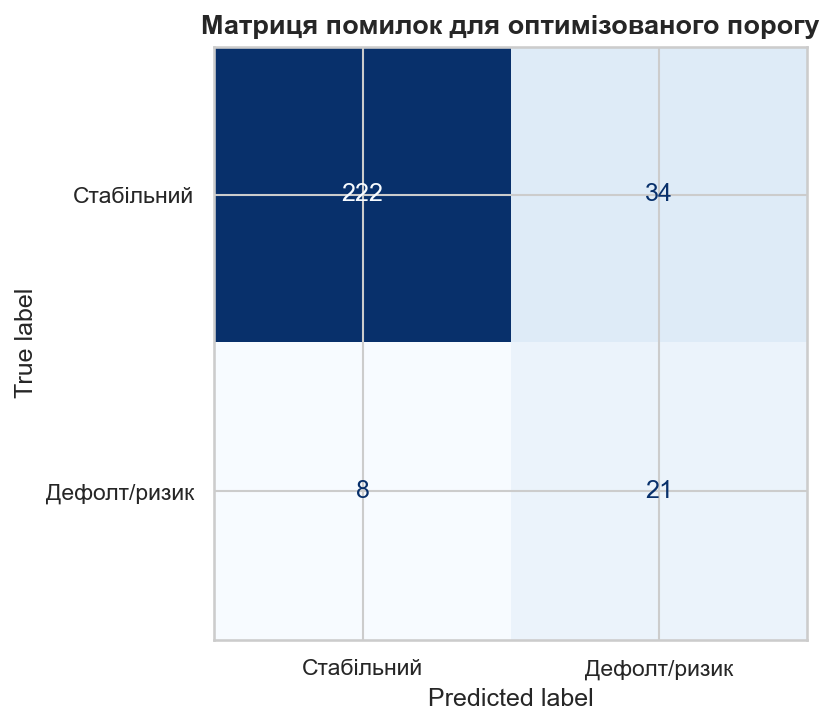

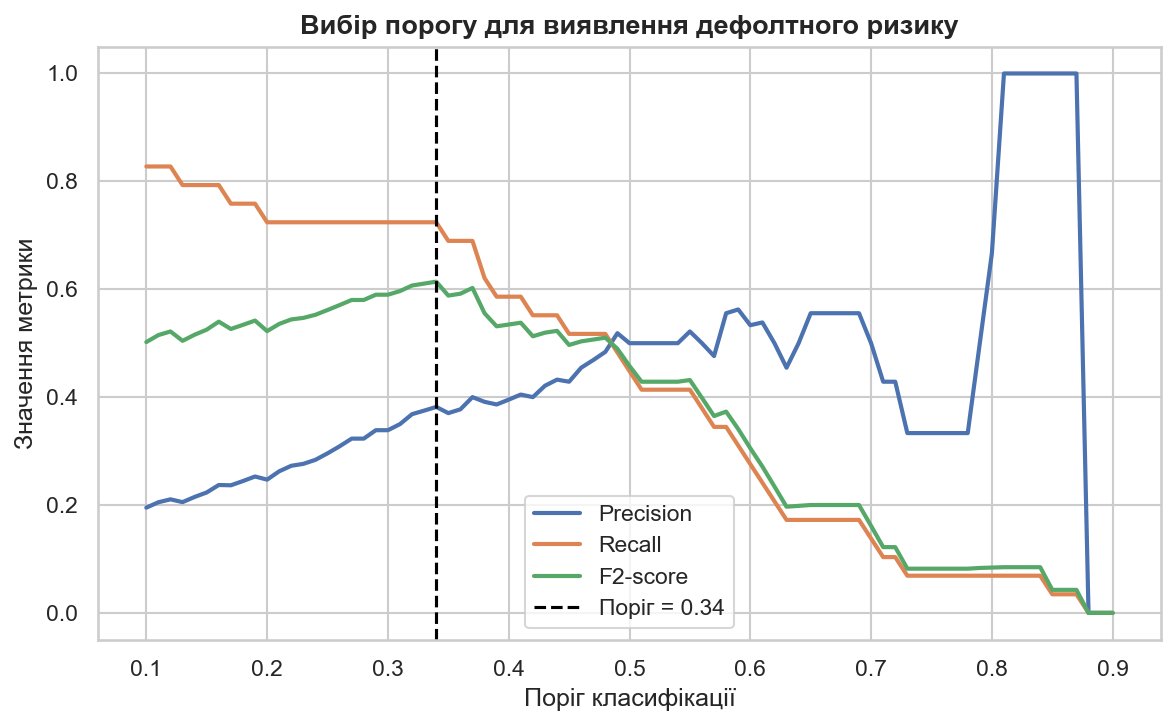

In [ ]:
print("--- 5.1. Обґрунтований вибір порогу для фінальної XGBoost-моделі ---")

threshold_grid = []
for threshold in np.arange(0.10, 0.91, 0.01):
    threshold_grid.append(evaluate_model('XGBoost final', final_probs, threshold=threshold))

threshold_report = pd.DataFrame(threshold_grid)
best_f2_row = threshold_report.loc[threshold_report['F2_default'].idxmax()]
recommended_threshold = float(best_f2_row['threshold'])
optimized_preds = (final_probs >= recommended_threshold).astype(int)

print(f"PR-AUC фінальної XGBoost-моделі: {average_precision_score(y_test, final_probs):.4f}")
print(f"Рекомендований поріг за максимумом F2-score: {recommended_threshold:.2f}")
print("\nНайкращі пороги за F2-score для фінальної XGBoost-моделі:")
display(threshold_report.sort_values('F2_default', ascending=False).head(10).round(3))

print("\nЗвіт класифікації для оптимізованого порогу:")
print(classification_report(y_test, optimized_preds))

cm = confusion_matrix(y_test, optimized_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Стабільний', 'Дефолт/ризик'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Матриця помилок для оптимізованого порогу', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(threshold_report['threshold'], threshold_report['precision_default'], label='Precision', lw=2)
plt.plot(threshold_report['threshold'], threshold_report['recall_default'], label='Recall', lw=2)
plt.plot(threshold_report['threshold'], threshold_report['F2_default'], label='F2-score', lw=2)
plt.axvline(recommended_threshold, color='black', linestyle='--', label=f'Поріг = {recommended_threshold:.2f}')
plt.xlabel('Поріг класифікації')
plt.ylabel('Значення метрики')
plt.title('Вибір порогу для виявлення дефолтного ризику', fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
print("--- 5.2. Підсумкові таблиці вибору моделі та фінальної XGBoost-моделі ---")

print("Порівняння моделей після підбору найкращого порогу за F2-score:")
display(best_threshold_comparison.round(3))

final_model_summary = pd.DataFrame([
    evaluate_model('XGBoost final, threshold 0.50', final_probs, threshold=0.50),
    evaluate_model('XGBoost final, threshold 0.30', final_probs, threshold=0.30),
    evaluate_model(f'XGBoost final, F2 threshold {recommended_threshold:.2f}', final_probs, threshold=recommended_threshold),
])

print("Фінальна XGBoost-модель при різних порогах:")
display(final_model_summary.round(3))

best_overall = best_threshold_comparison.iloc[0]
print(
    f"Висновок: після однакового підбору порогу за F2-score найкращий результат показала модель "
    f"{best_overall['model']} з F2-score = {best_overall['F2_default']:.3f}. "
    "Для теми роботи важливо не лише класифікувати банки, а й виявити фінансові індикатори "
    "підвищеного ризику. Тому фінальна інтерпретація виконується через SHAP-аналіз XGBoost-моделі, "
    "яка також має найкращі інтегральні метрики ранжування ризику ROC-AUC та PR-AUC."
)

--- 5.2. Підсумкові таблиці вибору моделі та фінальної XGBoost-моделі ---
Порівняння моделей після підбору найкращого порогу за F2-score:


,model,threshold,ROC-AUC,PR-AUC,precision_default,recall_default,F1_default,F2_default,balanced_accuracy,threshold_type
0,XGBoost,0.28,0.844,0.447,0.368,0.724,0.488,0.607,0.792,best_F2
1,Logistic Regression,0.26,0.802,0.345,0.188,1.000,0.317,0.537,0.756,best_F2
2,Random Forest,0.17,0.758,0.259,0.183,0.793,0.297,0.475,0.695,best_F2


Фінальна XGBoost-модель при різних порогах:


,model,threshold,ROC-AUC,PR-AUC,precision_default,recall_default,F1_default,F2_default,balanced_accuracy
0,"XGBoost final, threshold 0.50",0.50,0.839,0.438,0.500,0.448,0.473,0.458,0.699
1,"XGBoost final, threshold 0.30",0.30,0.839,0.438,0.339,0.724,0.462,0.590,0.782
2,"XGBoost final, F2 threshold 0.34",0.34,0.839,0.438,0.382,0.724,0.500,0.614,0.796


Висновок: після однакового підбору порогу за F2-score найкращий результат показала модель XGBoost з F2-score = 0.607. Для теми роботи важливо не лише класифікувати банки, а й виявити фінансові індикатори підвищеного ризику. Тому фінальна інтерпретація виконується через SHAP-аналіз XGBoost-моделі, яка також має найкращі інтегральні метрики ранжування ризику ROC-AUC та PR-AUC.


--- 6. Інтерпретація рішень моделі та ключові індикатори ризику (SHAP) ---
Топ-10 ключових індикаторів ризику за SHAP:


,feature,indicator,mean_abs_shap
0,net_income,Чистий прибуток,1.0420
1,deposits,Депозити,0.4474
2,interest_income,Процентні доходи,0.4104
3,interest_expense,Процентні витрати,0.4012
4,equity,Власний капітал,0.2834
5,cash,Грошові кошти,0.1848
6,equity_ratio,Коефіцієнт капіталізації,0.1620
7,reserves_ratio,Частка резервів у кредитах,0.1418
8,loan_reserves,Резерви під кредити,0.1261
9,ROA,ROA,0.1128


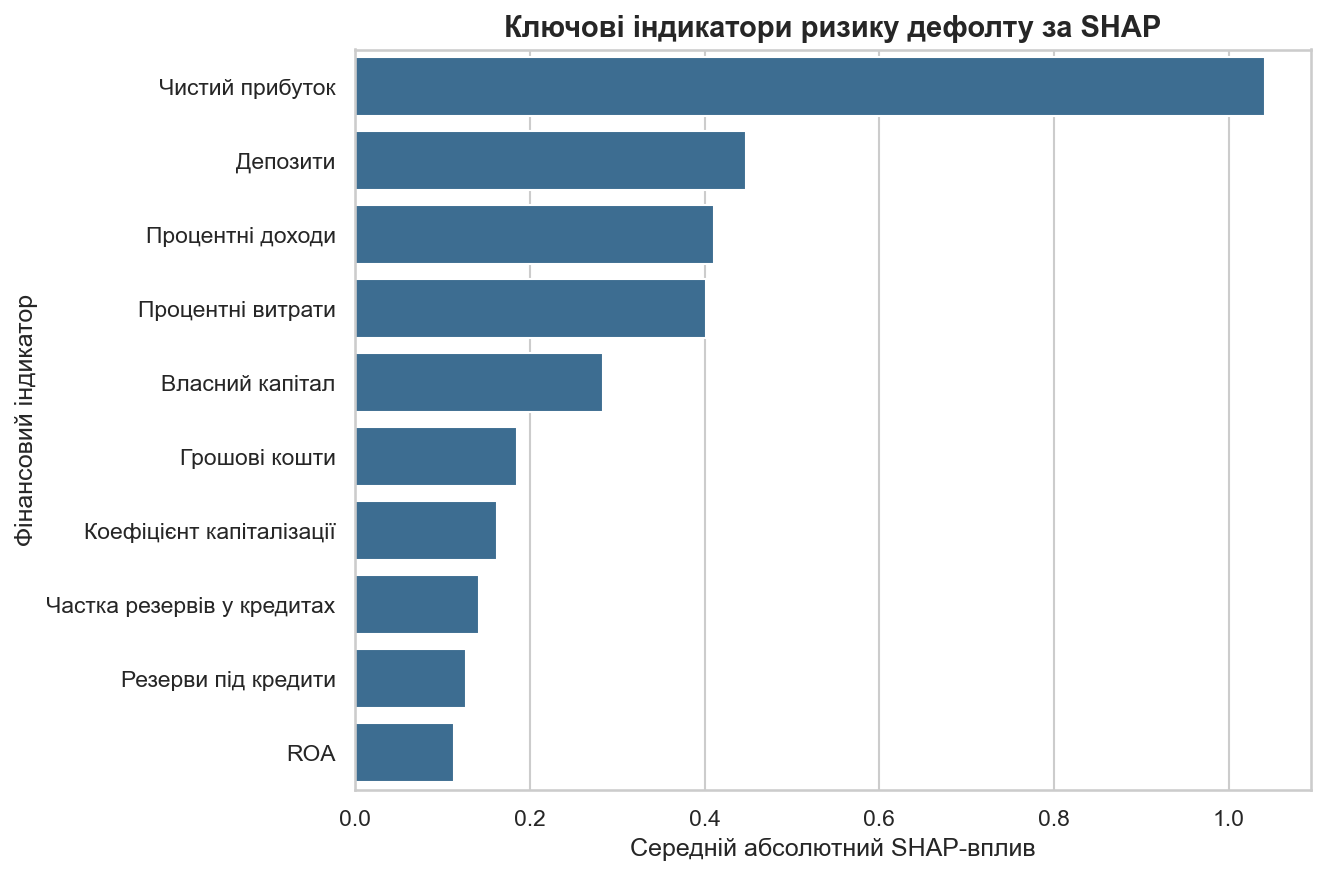

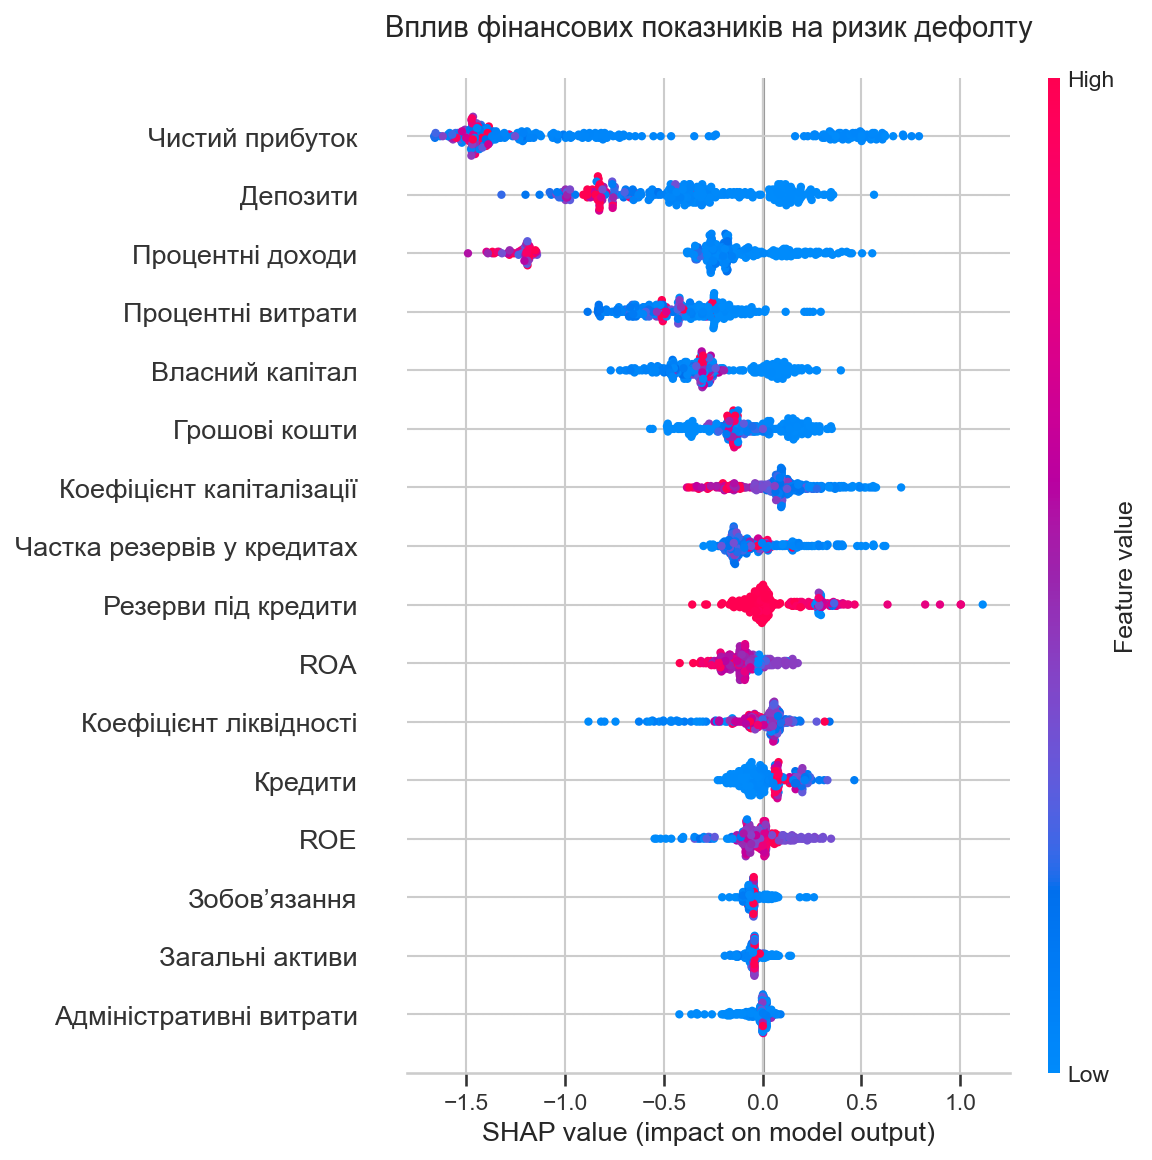

Інтерпретація: SHAP показує, які фінансові показники найбільше впливають на рішення моделі щодо підвищеного ризику дефолту. Це не є доведенням прямої причинності, але дозволяє виділити ключові індикатори ризику.


In [ ]:
import shap

print("--- 6. Інтерпретація рішень моделі та ключові індикатори ризику (SHAP) ---")

explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)

if isinstance(shap_values, list):
    shap_values_for_class = shap_values[1]
else:
    shap_values_for_class = shap_values

feature_labels = {
    'total_assets': 'Загальні активи',
    'cash': 'Грошові кошти',
    'loans': 'Кредити',
    'loan_reserves': 'Резерви під кредити',
    'total_liab': 'Зобов’язання',
    'deposits': 'Депозити',
    'equity': 'Власний капітал',
    'net_income': 'Чистий прибуток',
    'interest_income': 'Процентні доходи',
    'interest_expense': 'Процентні витрати',
    'admin_expenses': 'Адміністративні витрати',
    'ROA': 'ROA',
    'ROE': 'ROE',
    'equity_ratio': 'Коефіцієнт капіталізації',
    'reserves_ratio': 'Частка резервів у кредитах',
    'liquidity_ratio': 'Коефіцієнт ліквідності',
}

shap_importance = (
    pd.DataFrame({
        'feature': X_test.columns,
        'indicator': [feature_labels.get(col, col) for col in X_test.columns],
        'mean_abs_shap': np.abs(shap_values_for_class).mean(axis=0),
    })
    .sort_values('mean_abs_shap', ascending=False)
    .reset_index(drop=True)
)

print("Топ-10 ключових індикаторів ризику за SHAP:")
display(shap_importance.head(10).round(4))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=shap_importance.head(10),
    x='mean_abs_shap',
    y='indicator',
    color='#2f6f9f'
)
plt.xlabel('Середній абсолютний SHAP-вплив')
plt.ylabel('Фінансовий індикатор')
plt.title('Ключові індикатори ризику дефолту за SHAP', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_for_class, X_test, feature_names=[feature_labels.get(col, col) for col in X_test.columns], show=False)
plt.title("Вплив фінансових показників на ризик дефолту", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

print(
    "Інтерпретація: SHAP показує, які фінансові показники найбільше впливають "
    "на рішення моделі щодо підвищеного ризику дефолту. Це не є доведенням "
    "прямої причинності, але дозволяє виділити ключові індикатори ризику."
)

## 3. Conclusion & Business Impact
By aggregating and analyzing 16 years of raw financial reports, the model successfully identifies banks with an elevated risk of default based on their asset quality, liquidity, and equity ratios. 

**Future Enhancements (Next Steps):**
To address extreme "Concept Drift" caused by the 2022 systemic shocks, the model's accuracy could be further improved by integrating macroeconomic factors (e.g., NBU Key Rate, UAH/USD volatility, and inflation indices) directly into the feature set.